In [1]:
%pip install xgboost pandas numpy matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


# Практическая работа №8
## Градиентный бустинг и сравнение моделей

**Уровень:** A

**Датасет:** Abalone

**Целевая переменная:** Rings

### Цель работы

Обучить модель градиентного бустинга XGBoost,
использовать раннюю остановку (Early Stopping)
и сравнить результаты со случайным лесом из ПР-7.

### Задачи

1. Загрузить датасет Abalone.
2. Выполнить предварительную обработку данных.
3. Разделить данные на train, validation и test.
4. Обучить Random Forest.
5. Обучить XGBoost с ранней остановкой.
6. Сравнить MAE, RMSE, R² и время обучения.
7. Сформулировать выводы.

In [2]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
import xgboost as xgb

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

RANDOM_STATE = 42

print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("XGBoost:", xgb.__version__)
print("Random State:", RANDOM_STATE)

Python: 3.14.10
Pandas: 3.1.1
Scikit-learn: 1.9.1
XGBoost: 3.4.1
Random State: 42


In [3]:
possible_paths = [
    Path("../data/abalone.data.csv"),
    Path("data/abalone.data.csv")
]

data_path = next(
    (path for path in possible_paths if path.exists()),
    None
)

if data_path is None:
    raise FileNotFoundError(
        "Не найден файл data/abalone.data.csv"
    )

df = pd.read_csv(data_path)

print("Размер датасета:", df.shape)
print("Столбцы:", df.columns.tolist())

display(df.head())

Размер датасета: (4177, 9)
Столбцы: ['gender', 'Length', 'Diameter', 'Height', 'Whole weight', 'Shucked weight', 'Viscera weight', 'Shell weight', 'Rings']


,gender,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,Rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


In [4]:
target = "Rings"

X = df.drop(columns=[target])
y = df[target]

X = pd.get_dummies(
    X,
    columns=["gender"],
    dtype=int
)

X = X.astype(float)

print("Признаки X:", X.shape)
print("Целевая переменная y:", y.shape)

display(X.head())

Признаки X: (4177, 10)
Целевая переменная y: (4177,)


,Length,Diameter,Height,Whole weight,Shucked weight,Viscera weight,Shell weight,gender_F,gender_I,gender_M
0,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,0.0,0.0,1.0
1,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,0.0,0.0,1.0
2,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,1.0,0.0,0.0
3,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,0.0,0.0,1.0
4,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,0.0,1.0,0.0


In [5]:
# То же исходное разбиение, что и в ПР-7
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE
)

# Дополнительная выборка для Early Stopping
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=RANDOM_STATE
)

print("Исходная обучающая выборка:", len(X_train))
print("Обучение моделей:", len(X_fit))
print("Валидация:", len(X_val))
print("Тест:", len(X_test))

Исходная обучающая выборка: 3341
Обучение моделей: 2672
Валидация: 669
Тест: 836


In [6]:
rf = RandomForestRegressor(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=4
)

start_time = time.perf_counter()

rf.fit(X_fit, y_fit)

rf_time = time.perf_counter() - start_time

print("Random Forest обучен успешно")
print(f"Время обучения: {rf_time:.4f} секунд")

Random Forest обучен успешно
Время обучения: 0.4955 секунд


In [7]:
boost = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.9,
    colsample_bytree=0.9,
    objective="reg:squarederror",
    tree_method="hist",
    eval_metric="rmse",
    early_stopping_rounds=20,
    random_state=RANDOM_STATE,
    n_jobs=4
)

start_time = time.perf_counter()

boost.fit(
    X_fit,
    y_fit,
    eval_set=[
        (X_fit, y_fit),
        (X_val, y_val)
    ],
    verbose=False
)

boost_time = time.perf_counter() - start_time

print("XGBoost обучен успешно")
print(f"Время обучения: {boost_time:.4f} секунд")
print(f"Лучшая итерация: {boost.best_iteration + 1}")
print(
    "Всего выполнено итераций:",
    boost.get_booster().num_boosted_rounds()
)
print(f"Лучший RMSE на валидации: {boost.best_score:.4f}")

XGBoost обучен успешно
Время обучения: 0.2564 секунд
Лучшая итерация: 80
Всего выполнено итераций: 100
Лучший RMSE на валидации: 2.0990


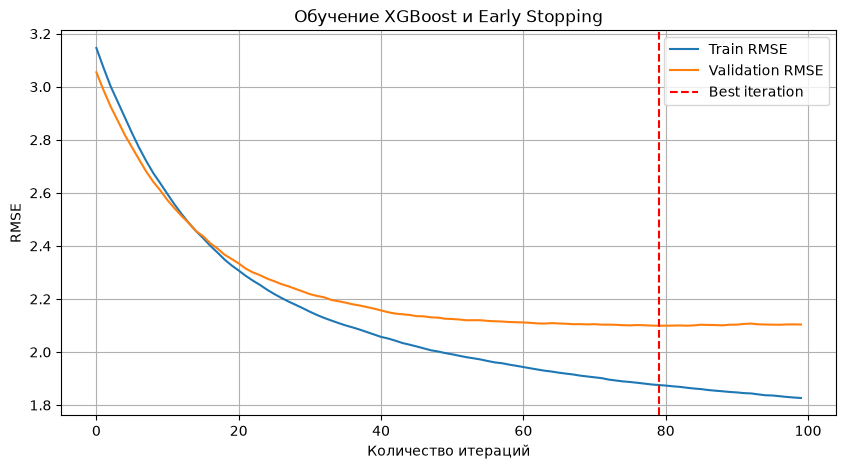

In [8]:
history = boost.evals_result()

train_rmse = history["validation_0"]["rmse"]
val_rmse = history["validation_1"]["rmse"]

plt.figure(figsize=(10, 5))

plt.plot(
    train_rmse,
    label="Train RMSE"
)

plt.plot(
    val_rmse,
    label="Validation RMSE"
)

plt.axvline(
    x=boost.best_iteration,
    color="red",
    linestyle="--",
    label="Best iteration"
)

plt.xlabel("Количество итераций")
plt.ylabel("RMSE")
plt.title("Обучение XGBoost и Early Stopping")
plt.legend()
plt.grid(True)

plt.show()

In [9]:
def evaluate_model(model, name, training_time):
    train_pred = model.predict(X_fit)
    test_pred = model.predict(X_test)

    return {
        "Модель": name,

        "MAE train": mean_absolute_error(
            y_fit, train_pred
        ),
        "MAE test": mean_absolute_error(
            y_test, test_pred
        ),

        "RMSE train": np.sqrt(
            mean_squared_error(y_fit, train_pred)
        ),
        "RMSE test": np.sqrt(
            mean_squared_error(y_test, test_pred)
        ),

        "R² train": r2_score(y_fit, train_pred),
        "R² test": r2_score(y_test, test_pred),

        "Время обучения (с)": training_time
    }


results = [
    evaluate_model(rf, "Random Forest", rf_time),
    evaluate_model(boost, "XGBoost", boost_time)
]

comparison = pd.DataFrame(results)

display(comparison.round(4))

,Модель,MAE train,MAE test,RMSE train,RMSE test,R² train,R² test,Время обучения (с)
0,Random Forest,0.5719,1.5875,0.8151,2.2499,0.9362,0.5324,0.4955
1,XGBoost,1.3455,1.5566,1.8756,2.2247,0.6620,0.5428,0.2564


In [10]:
best_index = comparison["RMSE test"].idxmin()

best_model = comparison.loc[
    best_index, "Модель"
]

print("Лучшая модель по RMSE на тесте:", best_model)

print("\nСравнение моделей:")
display(
    comparison.sort_values(
        by="RMSE test"
    ).round(4)
)

Лучшая модель по RMSE на тесте: XGBoost

Сравнение моделей:


,Модель,MAE train,MAE test,RMSE train,RMSE test,R² train,R² test,Время обучения (с)
1,XGBoost,1.3455,1.5566,1.8756,2.2247,0.6620,0.5428,0.2564
0,Random Forest,0.5719,1.5875,0.8151,2.2499,0.9362,0.5324,0.4955


## Вывод

В ходе практической работы №8 были обучены
две модели: Random Forest и XGBoost.

Обе модели использовали один датасет Abalone,
одинаковые признаки, обучающую и тестовую выборки,
а также random_state=42.

Для XGBoost была применена ранняя остановка,
которая позволяет прекратить добавление деревьев,
если качество на валидационных данных перестаёт улучшаться.

### Отличие Random Forest от Gradient Boosting

Случайный лес обучает множество деревьев независимо
друг от друга, а затем усредняет их предсказания.
Это помогает уменьшить разброс и повысить
устойчивость результата.

Градиентный бустинг строит деревья последовательно.
Каждое новое дерево пытается исправить ошибки
текущей модели, постепенно улучшая предсказания.

### Итоговое сравнение

На тестовых данных модели сравнивались по
MAE, RMSE и R², а также по времени обучения.

Лучшая модель определяется по итоговой
таблице результатов.